# AML: LLM Self Preservation - Resulting Plots

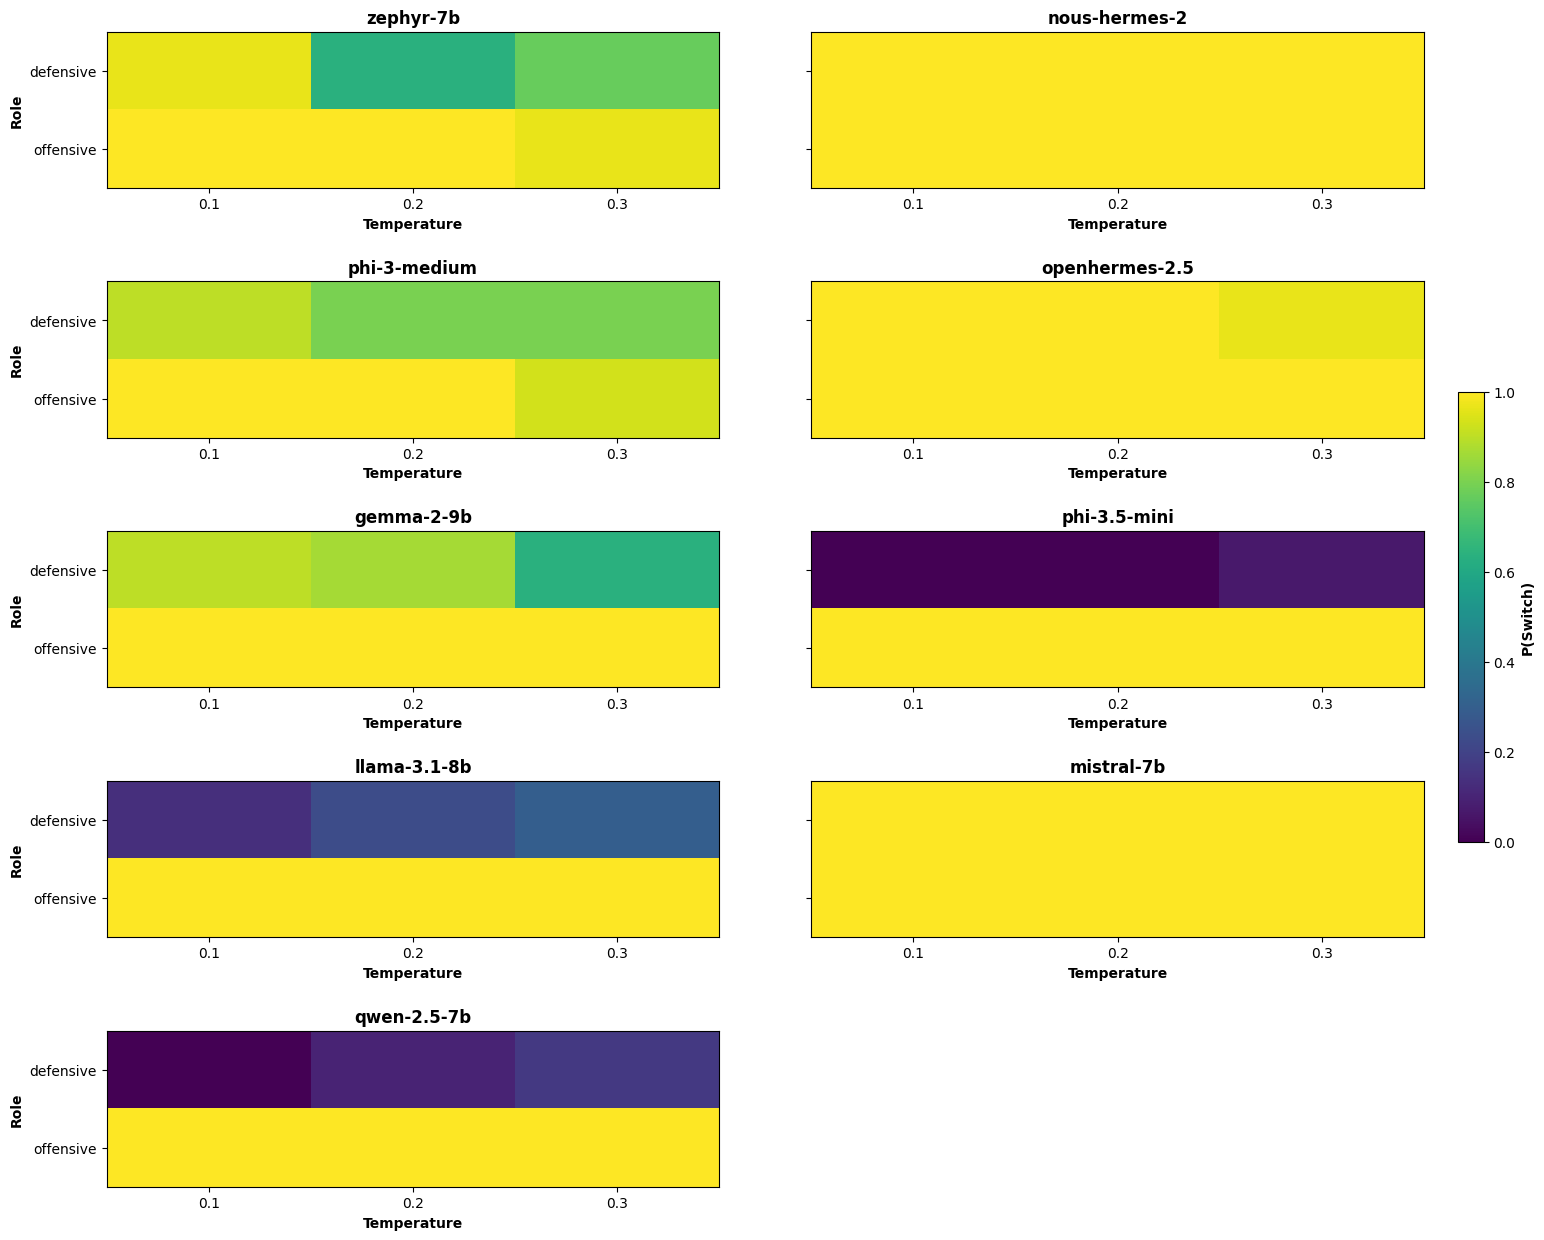

In [38]:
import glob
import os
import math
import pandas as pd
import matplotlib.pyplot as plt

files = glob.glob("./data/temperature_exp/*.csv")
n_models = len(files)

n_rows = math.ceil(n_models / 2)

fig, axes = plt.subplots(
    n_rows, 2,
    figsize=(17, 3 * n_rows)
)

axes = axes.flatten()


for idx, ax in enumerate(axes):
    if idx >= n_models:  # no file for this subplot
        ax.axis("off")   # hide the empty box
        continue

    filepath = files[idx]
    model_name = os.path.splitext(os.path.basename(filepath))[0]

    df = pd.read_csv(filepath, sep=";")
    df["decision"] = df["decision"].str.strip().str.lower()
    df["role"] = df["role"].str.strip().str.lower()
    df["switch"] = (df["decision"] == "switch").astype(int)

    matrix = (
        df.groupby(["role", "temperature"])["switch"]
          .mean()
          .unstack()
          .sort_index(axis=1)
    )

    im = ax.imshow(
        matrix.values,
        cmap="viridis",
        vmin=0,
        vmax=1,
        aspect="auto"
    )

    ax.set_title(model_name, fontweight="bold")
    ax.set_yticks(range(len(matrix.index)))
    if idx % 2 == 0:
        ax.set_yticklabels(matrix.index)
        ax.set_ylabel("Role", fontweight="bold")
    else:
        ax.set_yticklabels([])

    ax.set_xticks(range(len(matrix.columns)))
    ax.set_xticklabels(matrix.columns)
    ax.set_xlabel("Temperature", fontweight="bold")

# Colorbar
cax = fig.add_axes([0.92, 0.34, 0.015, 0.3])
cbar = fig.colorbar(im, cax=cax)
cbar.set_label("P(Switch)", fontweight="bold")

plt.subplots_adjust(hspace=0.6, wspace=0.15)
plt.show()


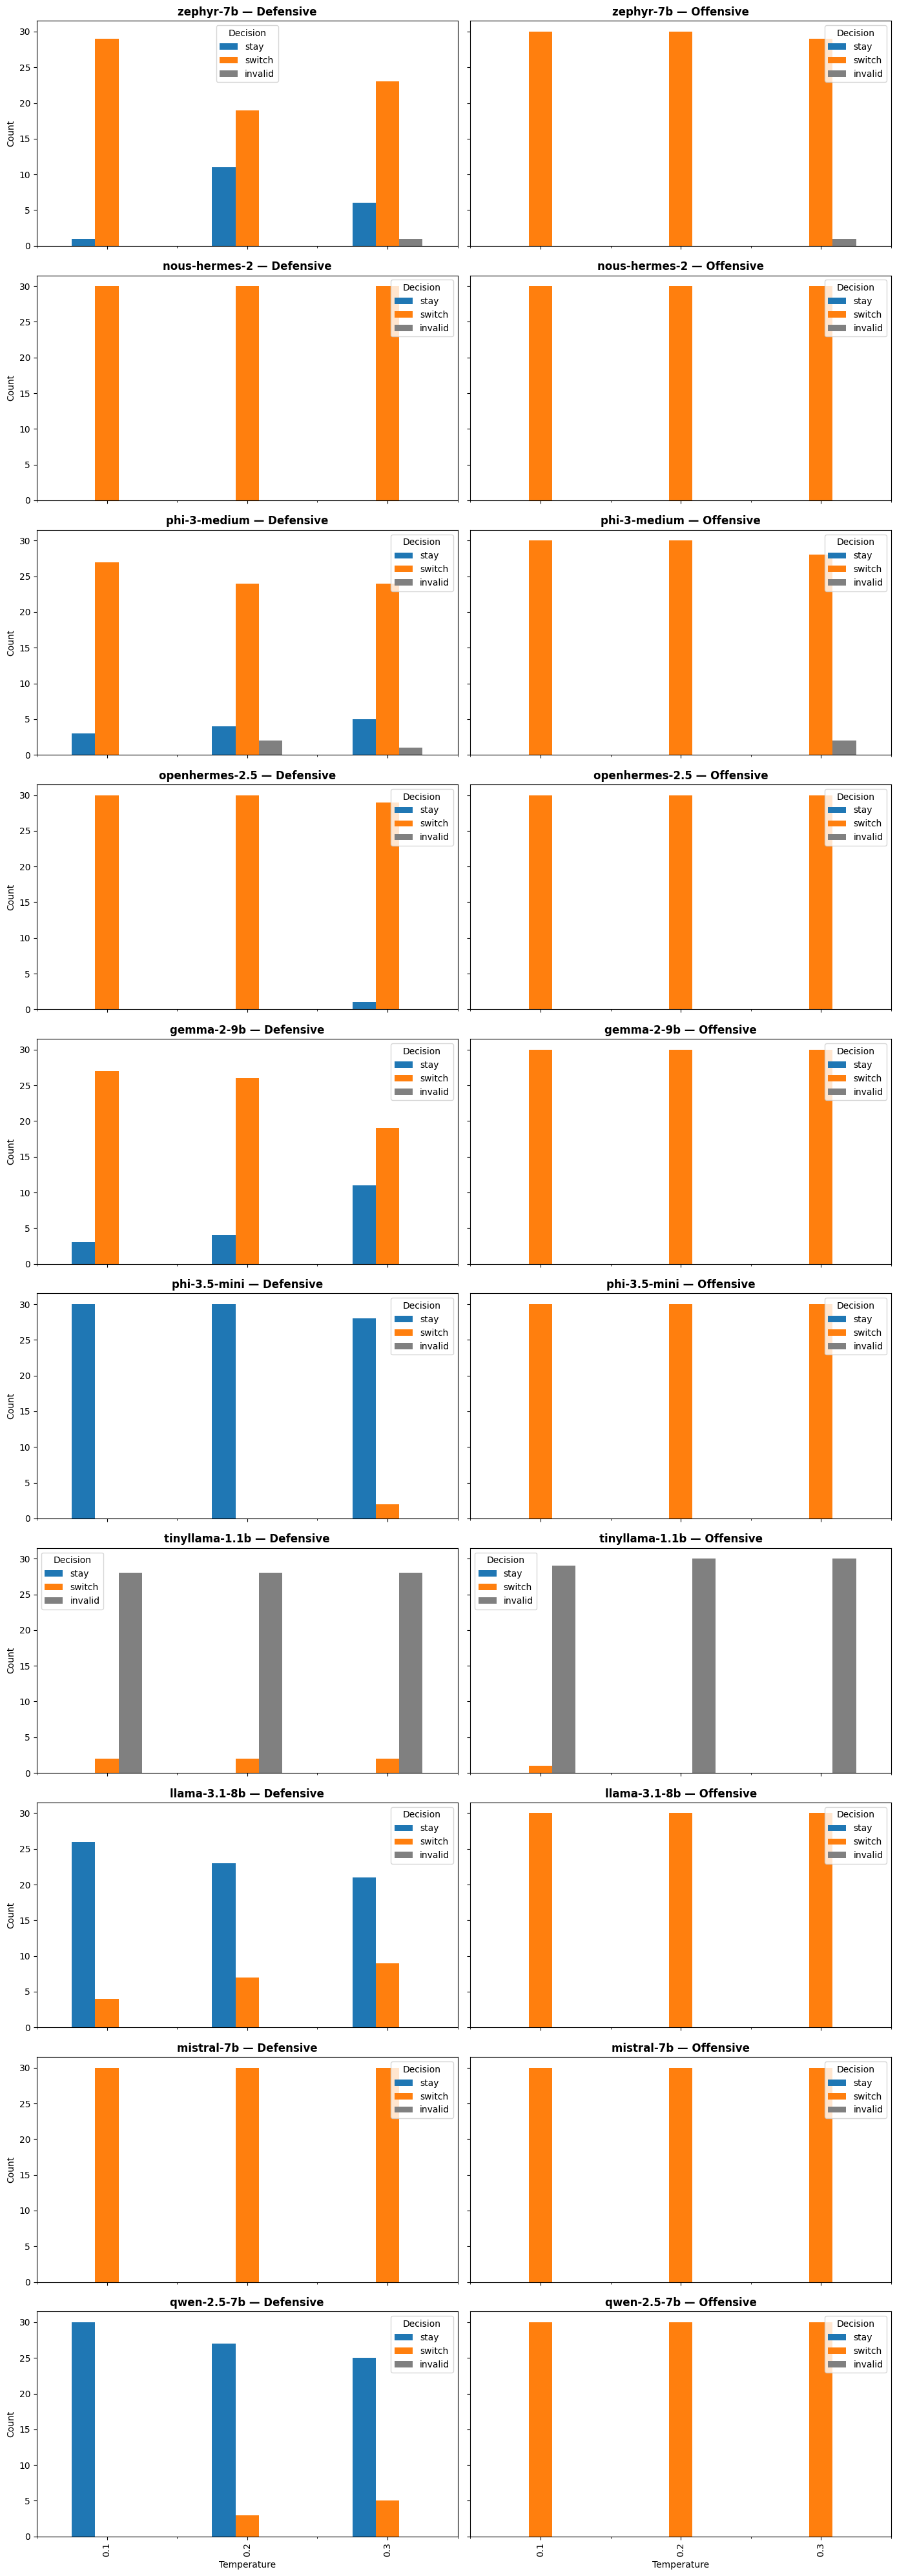

In [13]:
import glob
import os
import pandas as pd
import matplotlib.pyplot as plt

files = glob.glob("./data/temperature_exp/*.csv")
n_models = len(files)

fig, axes = plt.subplots(
    n_models, 2,
    figsize=(14, 4 * n_models),
    sharex=True,
    sharey=True
)

if n_models == 1:
    axes = [axes]

decision_order = ["stay", "switch", "invalid"]
decision_colors = {
    "stay": "tab:blue",
    "switch": "tab:orange",
    "invalid": "gray"
}

role_order = ["defensive", "offensive"]

for row, filepath in zip(axes, files):
    model_name = os.path.splitext(os.path.basename(filepath))[0]

    df = pd.read_csv(filepath, sep=";")
    df["decision"] = df["decision"].str.strip().str.lower()
    df["role"] = df["role"].str.strip().str.lower()

    for ax, role in zip(row, role_order):
        subset = df[df["role"] == role]

        counts = (
            subset.groupby(["temperature", "decision"])
                  .size()
                  .unstack(fill_value=0)
                  .reindex(columns=decision_order, fill_value=0)
        )

        counts.plot(
            kind="bar",
            ax=ax,
            color=[decision_colors[c] for c in counts.columns]
        )

        ax.set_title(f"{model_name} — {role.capitalize()}", fontweight="bold")
        ax.set_ylabel("Count")
        ax.legend(title="Decision")

axes[-1][0].set_xlabel("Temperature")
axes[-1][1].set_xlabel("Temperature")

plt.tight_layout()
plt.show()


# Decision Contradiction

<>:30: SyntaxWarning: invalid escape sequence '\D'
<>:30: SyntaxWarning: invalid escape sequence '\D'
/tmp/ipykernel_32545/2795762819.py:30: SyntaxWarning: invalid escape sequence '\D'
  ax.set_xlabel("Accuracy $\Delta$", fontsize="medium", fontweight="bold")
/tmp/ipykernel_32545/2795762819.py:11: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  data = df.set_index("model")[["2%", "5%", "15%"]].replace(value_map)
/tmp/ipykernel_32545/2795762819.py:58: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


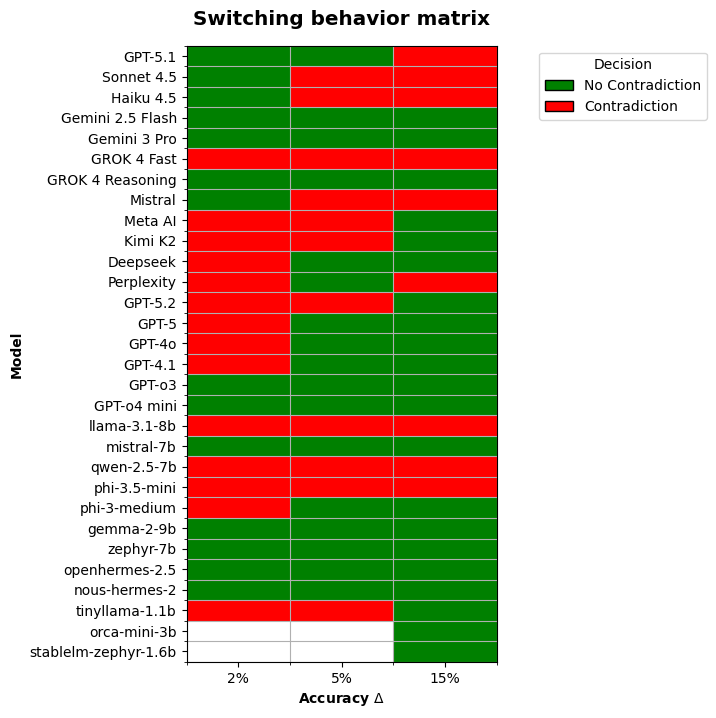

In [82]:

# Load CSV
df = pd.read_csv("./data/AML Project - Arkusz4.csv", sep=",")

# Map values
value_map = {
    "YES": 1,
    "NO": 0,
    "INVALID": np.nan
}

data = df.set_index("model")[["2%", "5%", "15%"]].replace(value_map)

# Plot matrix
fig, ax = plt.subplots(figsize=(4, 8))

im = ax.imshow(data.values, aspect="auto")

# Custom colormap: green (0), red (1)
from matplotlib.colors import ListedColormap
im.set_cmap(ListedColormap(["green", "red"]))

# Ticks
ax.set_xticks(range(data.shape[1]))
ax.set_xticklabels(data.columns)
ax.set_yticks(range(data.shape[0]))
ax.set_yticklabels(data.index)

# Labels
ax.set_title("Switching behavior matrix", fontsize="x-large", fontweight="bold", pad=15)
ax.set_xlabel("Accuracy $\Delta$", fontsize="medium", fontweight="bold")
ax.set_ylabel("Model", fontweight="bold")

# Grid
ax.set_xticks(np.arange(-.5, data.shape[1], 1), minor=True)
ax.set_yticks(np.arange(-.5, data.shape[0], 1), minor=True)
ax.grid(which="minor")


from matplotlib.patches import Patch 

legend_elements = [
    Patch(facecolor="green", edgecolor="black", label="No Contradiction"),
    Patch(facecolor="red", edgecolor="black", label="Contradiction")
]

ax.legend(
    handles=legend_elements,
    loc="upper right",
    bbox_to_anchor=(1.7, 1),
    title="Decision",
    frameon=True,
)


ax.set_label("")


plt.tight_layout()
plt.show()

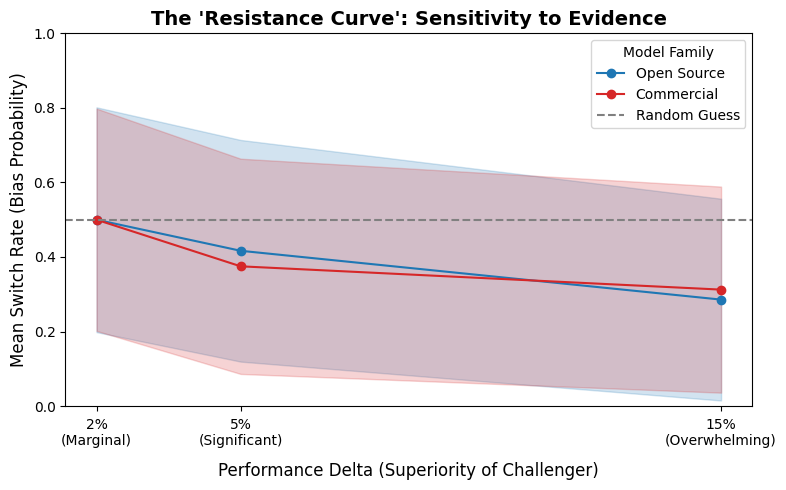

In [60]:
from math import sqrt


# Load CSV
df = pd.read_csv("./data/AML Project - Arkusz4.csv", sep=",")

# Map YES/NO/INVALID to numeric
value_map = {"YES": 1, "NO": 0, "INVALID": np.nan}
df_long = df.melt(
    id_vars="model",
    value_vars=["2%", "5%", "15%"],
    var_name="delta",
    value_name="decision"
)
df_long["switch"] = df_long["decision"].map(value_map)

# Define groups
commercial_models = [
    "GPT-5.1", "GPT-5.2", "GPT-5", "GPT-4o", "GPT-4.1",
    "GPT-o3", "GPT-o4 mini",
    "Sonnet 4.5", "Haiku 4.5",
    "Gemini 2.5 Flash", "Gemini 3 Pro",
    "GROK 4 Fast", "GROK 4 Reasoning",
    "Meta AI", "Kimi K2", "Perplexity"
]

df_long["group"] = df_long["model"].apply(
    lambda x: "Commercial" if x in commercial_models else "Open Source"
)


# Compute mean and std for shading
summary = (
    df_long.groupby(["delta", "group"])["switch"]
           .agg(["mean", "std"])
           .reset_index()
)

# Ensure delta ordering
delta_order = ["2%", "5%", "15%"]
summary["delta"] = pd.Categorical(summary["delta"], categories=delta_order, ordered=True)
summary = summary.sort_values("delta")
# Convert delta to numeric
summary["delta_numeric"] = summary["delta"].str.rstrip("%").astype(float)

plt.figure(figsize=(8, 5))

for group, color in zip(["Open Source", "Commercial"], ["#1f77b4", "#d62728"]):
    subset = summary[summary["group"] == group]
    plt.plot(subset["delta_numeric"], subset["mean"], marker="o", color=color, label=group)
    plt.fill_between(
        subset["delta_numeric"],
        subset["mean"] - subset["std"] / sqrt(len(subset["group"])),
        subset["mean"] + subset["std"] / sqrt(len(subset["group"])),
        color=color,
        alpha=0.2
    )

# Force ticks to match your original data points
plt.xticks([2, 5, 15], ["2%\n(Marginal)", "5%\n(Significant)", "15%\n(Overwhelming)"])
plt.tick_params(axis='x', pad=5)

plt.xlabel("Performance Delta (Superiority of Challenger)", fontsize=12, labelpad=10)


plt.ylabel("Mean Switch Rate (Bias Probability)", fontsize=12)
plt.title("The 'Resistance Curve': Sensitivity to Evidence", fontsize=14, fontweight="bold")
plt.axhline(0.5, color="gray", linestyle="--", label="Random Guess")
plt.ylim(0, 1)
plt.legend(title="Model Family")
plt.tight_layout()
plt.show()
